In [1]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
dane = pd.read_csv(
    "top10_stocks_data.csv",
    header=[0, 1],
    index_col=0,
    parse_dates=True
)

In [4]:
ceny_zamkniecia = dane["Close"]

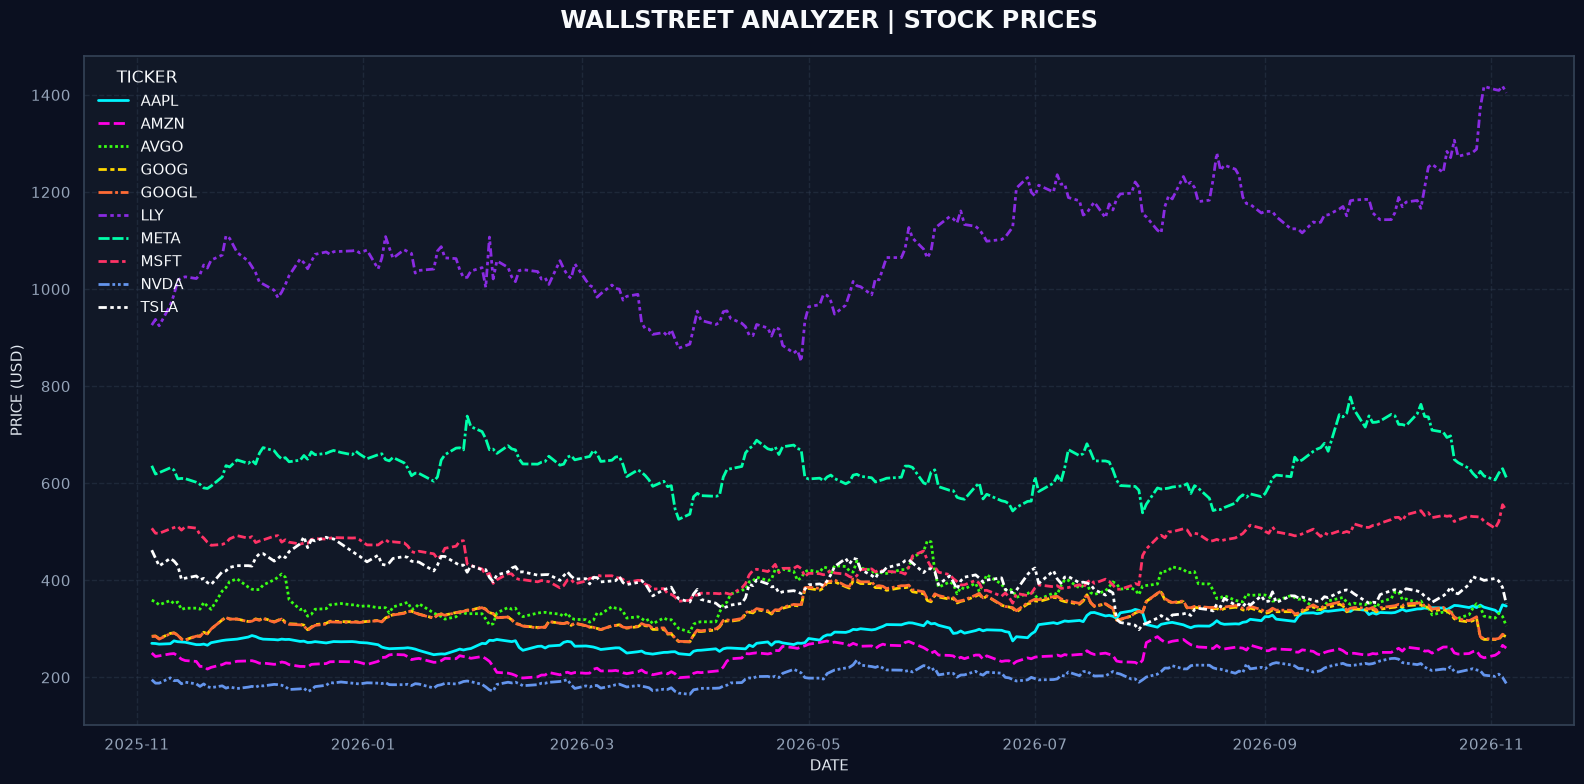

In [7]:
sns.set_theme(
    style="dark",
    context="notebook"
)

plt.rcParams.update({
    "figure.facecolor": "#0B1020",
    "axes.facecolor": "#111827",
    "axes.edgecolor": "#334155",
    "axes.labelcolor": "#E2E8F0",
    "text.color": "#F8FAFC",
    "xtick.color": "#94A3B8",
    "ytick.color": "#94A3B8",
    "grid.color": "#334155",
    "grid.alpha": 0.4,
    "font.family": "DejaVu Sans"
})

plt.figure(figsize=(16, 8))

kolory = [
    "#00F5FF",
    "#FF00E5",
    "#39FF14",
    "#FFD700",
    "#FF6B35",
    "#8A2BE2",
    "#00FFAA",
    "#FF3366",
    "#6495ED",
    "#FFFFFF"
]

sns.lineplot(
    data=ceny_zamkniecia,
    palette=kolory,
    linewidth=2
)

plt.title(
    "WALLSTREET ANALYZER | STOCK PRICES",
    fontsize=17,
    fontweight="bold",
    pad=20
)

plt.xlabel("DATE", fontsize=11)
plt.ylabel("PRICE (USD)", fontsize=11)

plt.grid(True, linestyle="--")
plt.legend(title="TICKER", frameon=False)

plt.tight_layout()
plt.show()

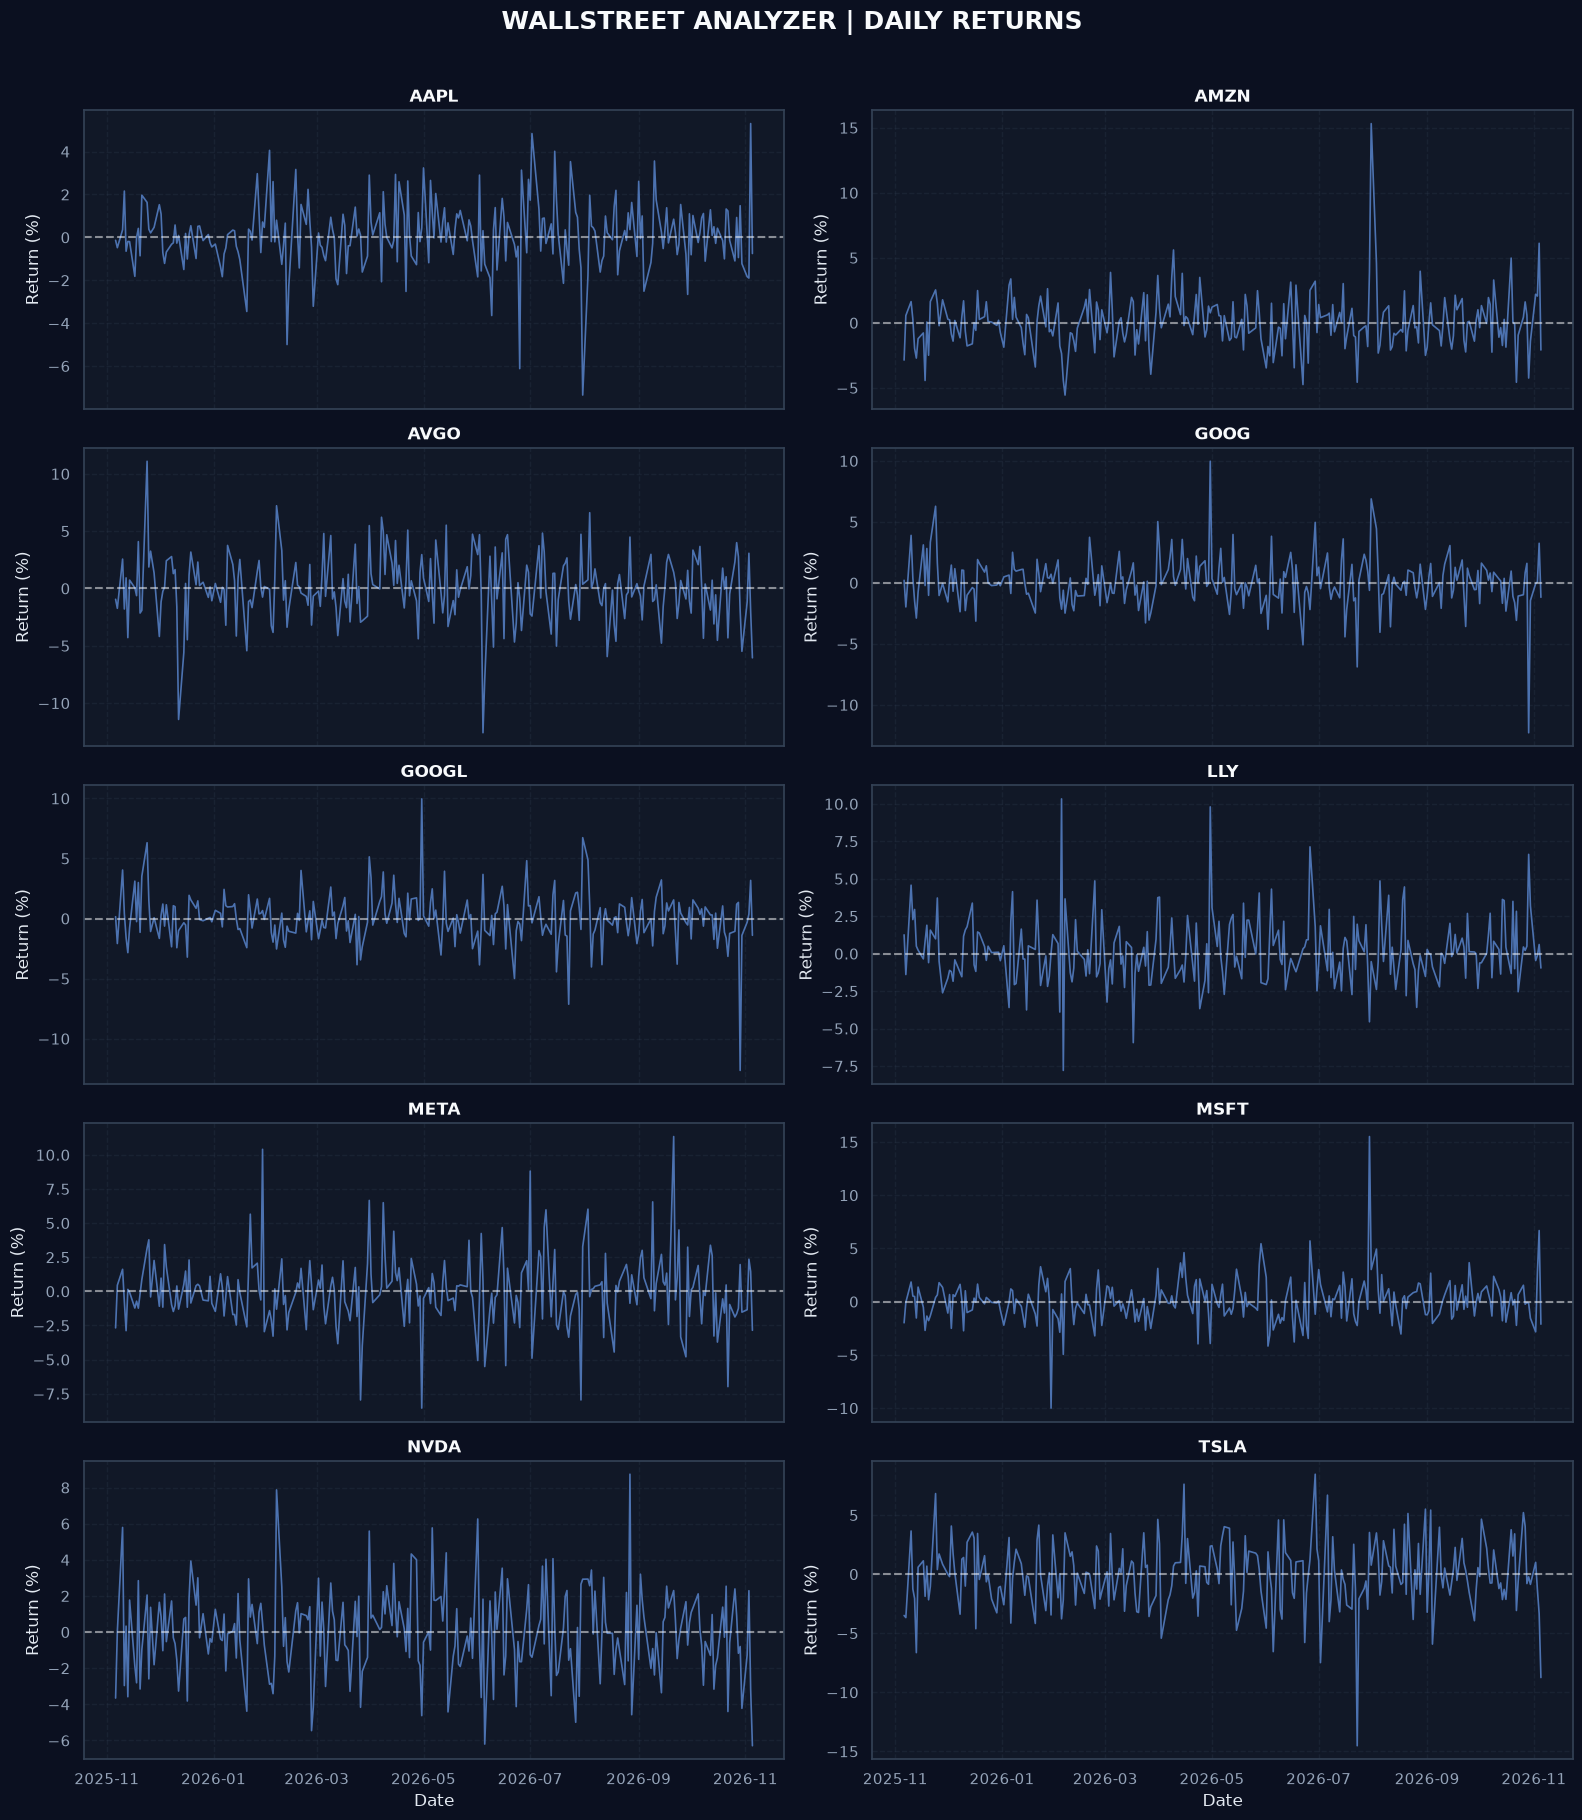

In [13]:
fig, axes = plt.subplots(5, 2, figsize=(16, 18), sharex=True)

for ax, ticker in zip(axes.flat, stopy_zwrotu.columns):
    sns.lineplot(
        x=stopy_zwrotu.index,
        y=stopy_zwrotu[ticker],
        ax=ax,
        linewidth=1.2
    )

    ax.axhline(0, color="white", linestyle="--", alpha=0.5)
    ax.set_title(ticker, fontweight="bold")
    ax.set_ylabel("Return (%)")
    ax.grid(True, linestyle="--", alpha=0.25)

plt.suptitle(
    "WALLSTREET ANALYZER | DAILY RETURNS",
    fontsize=18,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

In [14]:
znormalizowane_ceny = 100 * ceny_zamkniecia / ceny_zamkniecia.iloc[0]
znormalizowane_ceny.iloc[0]

Ticker
AAPL     100.0
AMZN     100.0
AVGO     100.0
GOOG     100.0
GOOGL    100.0
LLY      100.0
META     100.0
MSFT     100.0
NVDA     100.0
TSLA     100.0
Name: 2025-11-05 00:00:00, dtype: float64

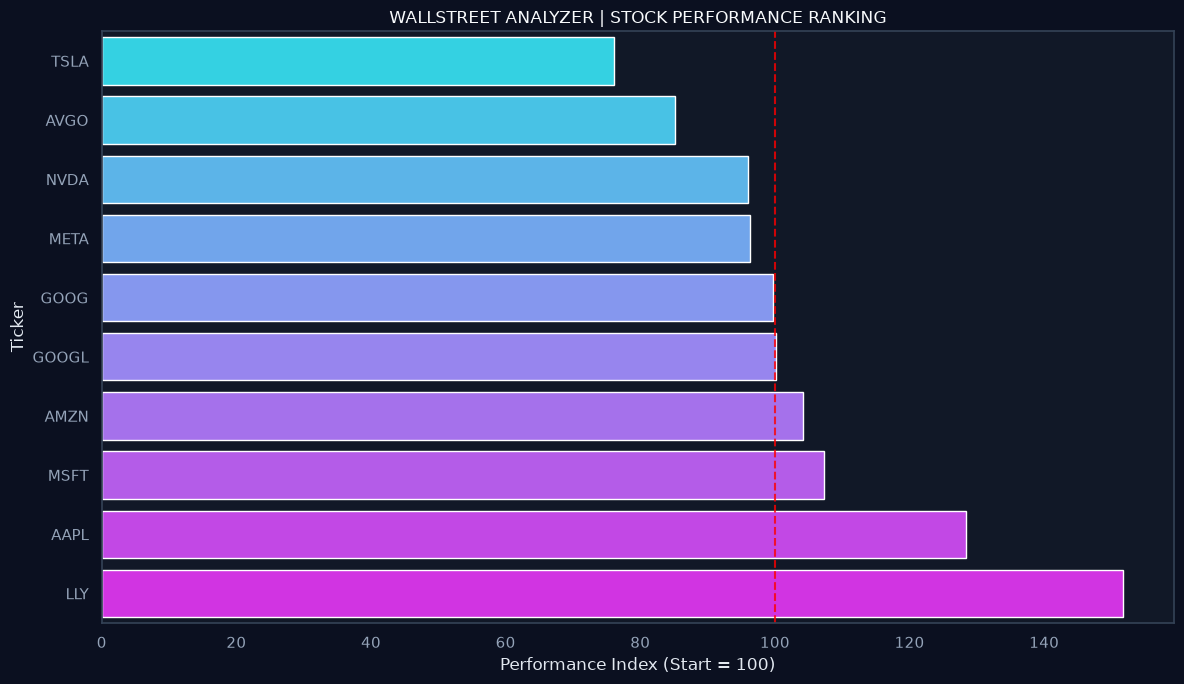

In [16]:
koncowe_wyniki = znormalizowane_ceny.iloc[-1].sort_values()

plt.figure(figsize=(12, 7))

sns.barplot(
    x=koncowe_wyniki.values,
    y=koncowe_wyniki.index,
    hue=koncowe_wyniki.index,
    palette="cool",
    legend=False
)

plt.axvline(100, color="red", linestyle="--", alpha=0.8)

plt.title("WALLSTREET ANALYZER | STOCK PERFORMANCE RANKING")
plt.xlabel("Performance Index (Start = 100)")
plt.ylabel("Ticker")

plt.tight_layout()
plt.show()

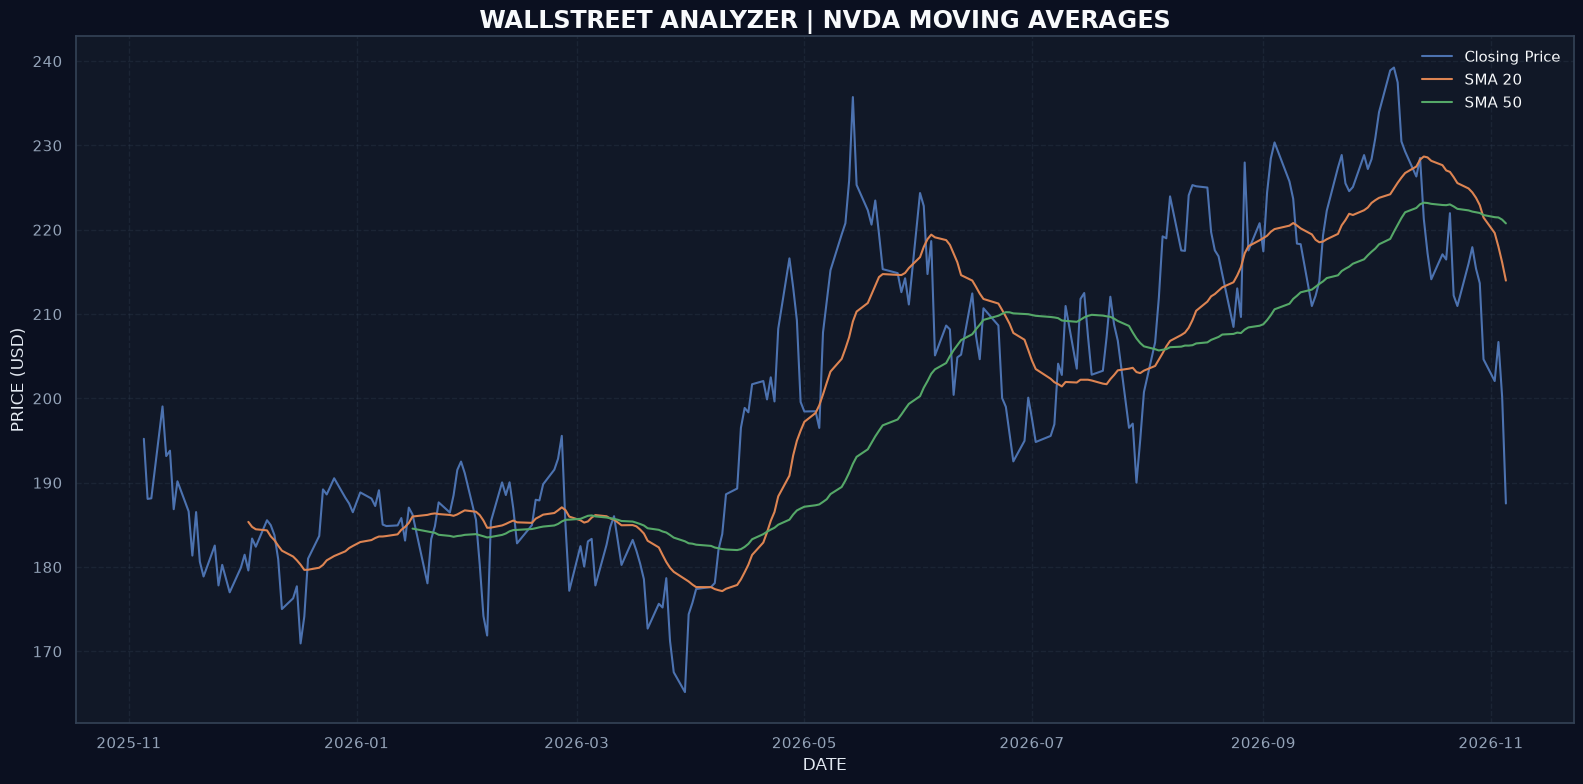

In [17]:
sma_20 = pd.read_csv("dane/sma_20.csv", index_col=0, parse_dates=True)
sma_50 = pd.read_csv("dane/sma_50.csv", index_col=0, parse_dates=True)

ticker = "NVDA"

plt.figure(figsize=(16, 8))

sns.lineplot(data=ceny_zamkniecia[ticker], label="Closing Price")
sns.lineplot(data=sma_20[ticker], label="SMA 20")
sns.lineplot(data=sma_50[ticker], label="SMA 50")

plt.title(f"WALLSTREET ANALYZER | {ticker} MOVING AVERAGES",
          fontsize=17, fontweight="bold")
plt.xlabel("DATE")
plt.ylabel("PRICE (USD)")

plt.grid(True, linestyle="--", alpha=0.3)
plt.legend(frameon=False)
plt.tight_layout()
plt.show()

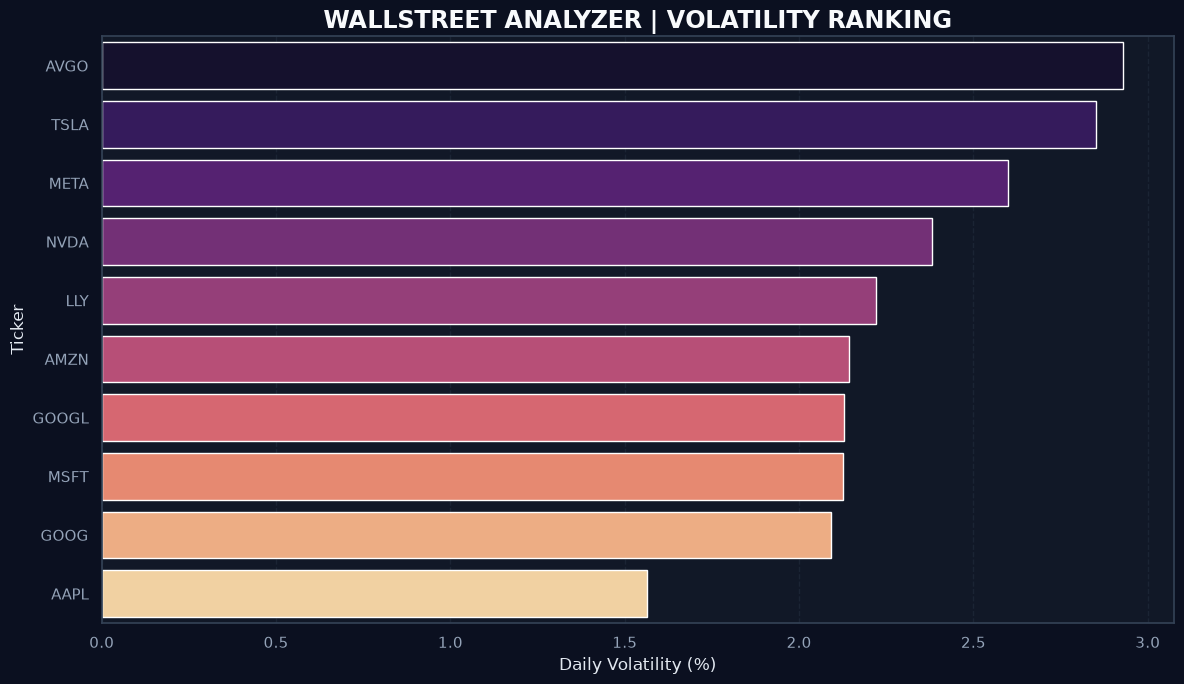

In [18]:
zmiennosc = pd.read_csv("dane/volatility.csv", index_col=0)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=zmiennosc.iloc[:, 0].sort_values(ascending=False).values,
    y=zmiennosc.iloc[:, 0].sort_values(ascending=False).index,
    hue=zmiennosc.iloc[:, 0].sort_values(ascending=False).index,
    palette="magma",
    legend=False
)

plt.title("WALLSTREET ANALYZER | VOLATILITY RANKING",
          fontsize=17, fontweight="bold")
plt.xlabel("Daily Volatility (%)")
plt.ylabel("Ticker")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

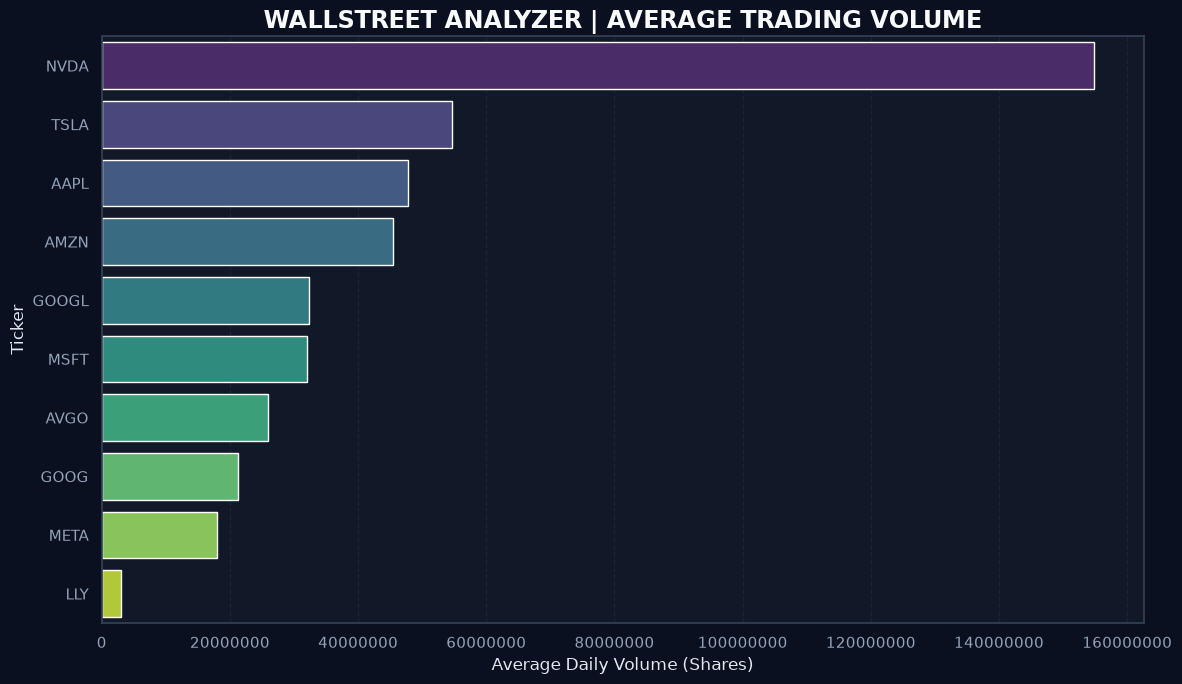

In [19]:
sredni_wolumen = pd.read_csv("dane/average_volume.csv", index_col=0)

plt.figure(figsize=(12, 7))

wolumen_rank = sredni_wolumen.iloc[:, 0].sort_values(ascending=False)

sns.barplot(
    x=wolumen_rank.values,
    y=wolumen_rank.index,
    hue=wolumen_rank.index,
    palette="viridis",
    legend=False
)

plt.title("WALLSTREET ANALYZER | AVERAGE TRADING VOLUME",
          fontsize=17, fontweight="bold")
plt.xlabel("Average Daily Volume (Shares)")
plt.ylabel("Ticker")
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()